# [핸즈온 머신러닝] Chapter 6 – 앙상블 학습과 랜덤 포레스트 (Ensemble Learning and Random Forests)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/jsmak/handson-mlp-study/blob/main/ch06/06_ensemble_learning_and_random_forests_kr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>
<br clear="left"/>

> **📚 출처 및 라이선스**
>
> - **원본 노트북**: [rickiepark/handson-mlp](https://github.com/rickiepark/handson-mlp) – [`06_ensemble_learning_and_random_forests.ipynb`](https://github.com/rickiepark/handson-mlp/blob/main/06_ensemble_learning_and_random_forests.ipynb) (박해선 님, 『핸즈온 머신러닝 with 사이킷런, 파이토치』 한빛미디어, 2026 예제 코드)
> - **원저작**: [ageron/handson-mlp](https://github.com/ageron/handson-mlp) (Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch*, O'Reilly)
> - **라이선스**: 원본 코드는 [Apache License 2.0](https://github.com/rickiepark/handson-mlp/blob/main/LICENSE)을 따릅니다.
> - **변경 사항**: 개인 학습(인프런 챌린지 복습) 목적으로 원본 노트북을 바탕으로 한국어 설명·주석을 추가하고, 셀 구성을 책의 절 번호에 맞춰 재정리했습니다. 책 본문은 포함하지 않습니다.

여러 예측기의 예측을 모아 더 좋은 예측을 만드는 **앙상블 학습**을 살펴봅니다. 투표 기반 분류기, 배깅·페이스팅, 랜덤 포레스트, 부스팅(AdaBoost, 그레이디언트 부스팅, HGB), 스태킹을 moons 데이터셋 등으로 실습합니다.

| 절 | 내용 | 주요 코드 |
|---|---|---|
| 6.1 | 투표 기반 분류기 (직접 / 간접 투표) | `VotingClassifier` |
| 6.2 | 배깅과 페이스팅, OOB 평가 | `BaggingClassifier`, `oob_score` |
| 6.3 | 랜덤 패치와 랜덤 서브스페이스 | `max_features`, `bootstrap_features` |
| 6.4 | 랜덤 포레스트, 엑스트라 트리, 특성 중요도 | `RandomForestClassifier`, `feature_importances_` |
| 6.5 | 부스팅 (AdaBoost, 그레이디언트 부스팅, HGB) | `AdaBoostClassifier`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor` |
| 6.6 | 스태킹 | `StackingClassifier` |

## **6.1 투표 기반 분류기**

여러 분류기의 예측을 모아 가장 많은 표를 얻은 클래스를 예측하는 것이 **직접 투표(hard voting)** 분류기입니다. 개별 분류기가 **약한 학습기(weak learner)** 여도 충분히 많고 다양하면 앙상블은 **강한 학습기(strong learner)** 가 될 수 있습니다. 그 이유는 **큰 수의 법칙(law of large numbers)** 으로 설명할 수 있습니다.

앞면이 나올 확률이 51%인 동전을 10,000번 던지는 실험을 10번 반복해 앞면 비율의 변화를 그립니다.

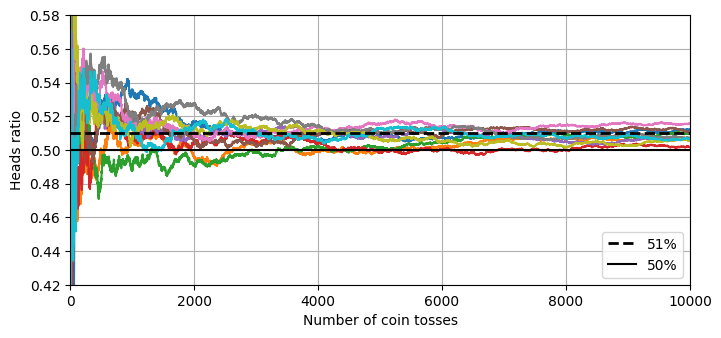

In [1]:
import matplotlib.pyplot as plt
import numpy as np

heads_proba = 0.51
rng = np.random.default_rng(seed=42)
coin_tosses = (rng.random((10000, 10)) < heads_proba).astype(np.int32)  # 10,000번 × 10번의 실험
cumulative_heads = coin_tosses.cumsum(axis=0)  # 던진 횟수까지의 누적 앞면 수
cumulative_heads_ratio = cumulative_heads / np.arange(1, 10001).reshape(-1, 1)

plt.figure(figsize=(8, 3.5))
plt.plot(cumulative_heads_ratio)
plt.plot([0, 10000], [0.51, 0.51], "k--", linewidth=2, label="51%")
plt.plot([0, 10000], [0.5, 0.5], "k-", label="50%")
plt.xlabel("Number of coin tosses")
plt.ylabel("Heads ratio")
plt.legend(loc="lower right")
plt.axis([0, 10000, 0.42, 0.58])
plt.grid()
plt.show()

→ 던지는 횟수가 늘수록 10번의 실험 모두 앞면 비율이 51%에 수렴하고 50%보다 높게 유지됩니다.

> 💡 앙상블은 예측기가 서로 **독립적**일수록 성능이 좋습니다. 각기 다른 알고리즘으로 훈련하면 서로 다른 종류의 오차를 만들 가능성이 높아집니다.

moons 데이터셋에 로지스틱 회귀, 랜덤 포레스트, SVC 세 분류기로 구성된 직접 투표 분류기를 훈련하고 개별 분류기와 정확도를 비교합니다.

In [2]:
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

voting_clf = VotingClassifier(estimators=[
        ("lr", LogisticRegression(random_state=42)),
        ("rf", RandomForestClassifier(random_state=42)),
        ("svc", SVC(random_state=42))
])
voting_clf.fit(X_train, y_train)

# 테스트 세트 첫 번째 샘플에 대한 개별 분류기의 예측과 투표 결과
print([clf.predict(X_test[:1]) for clf in voting_clf.estimators_])  # [array([1]), array([1]), array([0])]
print(voting_clf.predict(X_test[:1]))  # [1]

# 개별 분류기의 테스트 정확도
for name, clf in voting_clf.named_estimators_.items():
    print(name, "=", clf.score(X_test, y_test))
# lr = 0.864
# rf = 0.896
# svc = 0.896
print(voting_clf.score(X_test, y_test))  # 0.912

[array([1]), array([1]), array([0])]
[1]
lr = 0.864
rf = 0.896
svc = 0.896
0.912


→ 세 분류기가 1, 1, 0을 예측해 다수결로 1을 예측했고, 투표 기반 분류기(0.912)가 개별 분류기보다 정확도가 높습니다.

모든 분류기가 `predict_proba()`로 확률을 추정할 수 있으면 확률을 평균해 예측하는 **간접 투표(soft voting)** 를 쓸 수 있습니다.

`voting="soft"`로 바꾸고, SVC가 확률을 추정하도록 `probability=True`로 설정한 뒤 다시 훈련합니다.

In [3]:
voting_clf.voting = "soft"
voting_clf.named_estimators["svc"].probability = True  # SVC는 기본적으로 클래스 확률을 제공하지 않음
voting_clf.fit(X_train, y_train)
print(voting_clf.score(X_test, y_test))  # 0.92

0.92


→ 간접 투표로 92% 정확도를 얻었습니다.

> 💡 간접 투표는 추정 확률이 잘 보정되어 있을 때 잘 작동합니다. 그렇지 않다면 `sklearn.calibration.CalibratedClassifierCV`로 보정할 수 있습니다.

## **6.2 배깅과 페이스팅**

같은 알고리즘을 쓰되 훈련 세트의 서브셋을 랜덤하게 구성해 예측기를 다르게 학습시키는 방법입니다.

| 방식 | 샘플링 | 특징 |
|---|---|---|
| **배깅(bagging, bootstrap aggregating)** | 중복을 **허용** | 한 예측기가 같은 샘플을 여러 번 뽑을 수 있음 |
| **페이스팅(pasting)** | 중복을 **허용하지 않음** | 같은 샘플을 여러 예측기가 사용할 수는 있음 |

집계 함수는 분류일 때 **통계적 최빈값**, 회귀일 때 **평균**입니다. 앙상블은 단일 모델보다 편향은 비슷하지만 분산이 낮아집니다.

### **6.2.1 사이킷런의 배깅과 페이스팅**

결정 트리 500개로 배깅 앙상블을 훈련합니다. 각 트리는 중복을 허용해 뽑은 100개 샘플로 훈련됩니다. (페이스팅은 `bootstrap=False`)

In [4]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500,
                            max_samples=100, n_jobs=-1, random_state=42)  # n_jobs=-1: 모든 CPU 코어 사용
bag_clf.fit(X_train, y_train);  # 세미콜론: 모델 출력 생략

moons 데이터셋용 결정 경계 그리기 함수입니다. (6.5.1절 AdaBoost에서도 사용)

In [5]:
def plot_decision_boundary(clf, X, y, alpha=1.0):
    axes = [-1.5, 2.4, -1, 1.5]
    x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 100), np.linspace(axes[2], axes[3], 100))
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)

    plt.contourf(x1, x2, y_pred, alpha=0.3 * alpha, cmap="Wistia")  # 예측 영역 색칠
    plt.contour(x1, x2, y_pred, cmap="Greys", alpha=0.8 * alpha)    # 결정 경계선
    colors = ["#78785c", "#c47b27"]
    markers = ("o", "^")
    for idx in (0, 1):
        plt.plot(X[:, 0][y == idx], X[:, 1][y == idx],
                 color=colors[idx], marker=markers[idx], linestyle="none")
    plt.axis(axes)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)

단일 결정 트리와 배깅 앙상블(트리 500개)의 결정 경계를 비교합니다.

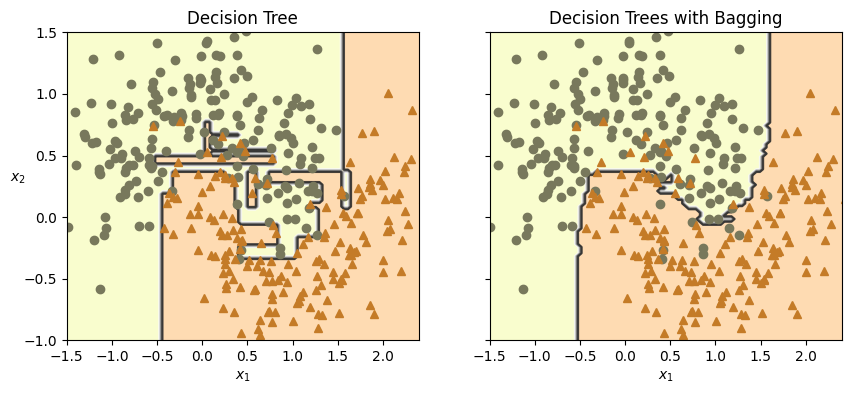

In [6]:
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf, X_train, y_train)
plt.title("Decision Tree")
plt.sca(axes[1])
plot_decision_boundary(bag_clf, X_train, y_train)
plt.title("Decision Trees with Bagging")
plt.ylabel("")
plt.show()

→ 앙상블은 훈련 세트의 오차 수는 비슷하지만 결정 경계가 덜 불규칙합니다. 즉, 비슷한 편향에서 더 작은 분산을 만들어 일반화가 더 잘 됩니다.

### **6.2.2 OOB 평가**

배깅에서 각 예측기는 훈련 샘플의 약 63%만 뽑고, 선택되지 않은 나머지 약 37%가 **OOB(out-of-bag) 샘플**입니다. 이를 검증 세트처럼 사용해 별도의 검증 세트 없이 앙상블을 평가할 수 있습니다.

`oob_score=True`로 배깅 앙상블을 훈련해 OOB 점수와 테스트 정확도, OOB 샘플의 클래스 확률을 확인합니다.

In [7]:
from sklearn.metrics import accuracy_score

bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500,
                            oob_score=True, n_jobs=-1, random_state=42)
bag_clf.fit(X_train, y_train)
print(bag_clf.oob_score_)  # 0.896

y_pred = bag_clf.predict(X_test)
print(accuracy_score(y_test, y_pred))  # 0.92

# 처음 세 훈련 샘플의 OOB 클래스 확률(%): [음성, 양성]
print(bag_clf.oob_decision_function_[:3].round(3) * 100)
# [[ 32.4  67.6]
#  [ 33.8  66.2]
#  [100.    0. ]]

0.896
0.92
[[ 32.4  67.6]
 [ 33.8  66.2]
 [100.    0. ]]


→ OOB 평가는 89.6%를 예상했지만 실제 테스트 정확도는 92%로, OOB 평가가 조금 비관적이었습니다. 첫 번째 훈련 샘플은 양성 클래스일 확률을 67.6%로 추정합니다.

## **6.3 랜덤 패치와 랜덤 서브스페이스**

`BaggingClassifier`는 특성 샘플링도 지원합니다. (`max_features`, `bootstrap_features`)

| 방식 | 샘플 | 특성 |
|---|---|---|
| **랜덤 패치(random patches)** | 샘플링 | 샘플링 |
| **랜덤 서브스페이스(random subspaces)** | 모두 사용 (`bootstrap=False`, `max_samples=1.0`) | 샘플링 (`bootstrap_features=True` 또는 `max_features` < 1.0) |

특성 샘플링은 편향을 조금 늘리는 대신 분산을 낮추며, 이미지처럼 고차원 데이터에서 유용합니다.

## **6.4 랜덤 포레스트**

랜덤 포레스트는 배깅(또는 페이스팅)을 적용한 결정 트리의 앙상블입니다. 노드를 분할할 때 전체 특성이 아니라 **랜덤하게 선택한 특성 후보($\sqrt{n}$개)** 중에서 최선의 특성을 찾아 무작위성을 더 주입합니다.

리프 노드가 최대 16개인 트리 500개로 랜덤 포레스트를 훈련하고, `BaggingClassifier`로 만든 거의 같은 앙상블과 예측을 비교합니다.

In [8]:
rnd_clf = RandomForestClassifier(n_estimators=500, max_leaf_nodes=16, n_jobs=-1, random_state=42)
rnd_clf.fit(X_train, y_train)
y_pred_rf = rnd_clf.predict(X_test)

# max_features="sqrt": 노드마다 √n개의 특성 후보를 랜덤하게 선택 → 랜덤 포레스트와 같은 구성
bag_clf = BaggingClassifier(DecisionTreeClassifier(max_features="sqrt", max_leaf_nodes=16),
                            n_estimators=500, n_jobs=-1, random_state=42)
bag_clf.fit(X_train, y_train)
y_pred_bag = bag_clf.predict(X_test)
print(np.all(y_pred_bag == y_pred_rf))  # True → 두 모델의 예측이 모두 같음

True


### **6.4.1 엑스트라 트리**

후보 특성마다 최적의 임곗값을 찾는 대신 **랜덤한 임곗값**으로 분할한 뒤 그중 최상의 분할을 고르는 극단적으로 랜덤한 트리의 앙상블을 **익스트림 랜덤 트리(extremely randomized trees)**, 줄여서 **엑스트라 트리(extra-trees)** 라고 합니다.

- 편향이 조금 늘어나는 대신 분산이 낮아집니다.
- 최적의 임곗값을 찾지 않으므로 랜덤 포레스트보다 훈련이 훨씬 빠릅니다.
- 사이킷런: `ExtraTreesClassifier` / `ExtraTreesRegressor` (`bootstrap` 기본값이 `False`인 것만 빼면 랜덤 포레스트와 같은 API)

### **6.4.2 특성 중요도**

사이킷런은 어떤 특성을 사용한 노드가 모든 트리에 걸쳐 평균적으로 불순도를 얼마나 감소시키는지(노드의 샘플 수로 가중 평균)로 특성 중요도를 측정하고, 합이 1이 되도록 정규화해 `feature_importances_`에 저장합니다.

붓꽃 데이터셋 전체(특성 4개)로 랜덤 포레스트를 훈련하고 특성 중요도를 큰 순서로 출력합니다.

In [9]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris(as_frame=True)
rnd_clf = RandomForestClassifier(n_estimators=500, random_state=42)
rnd_clf.fit(iris.data, iris.target)
pd.Series(rnd_clf.feature_importances_, index=iris.data.columns).sort_values(ascending=False)

petal length (cm)    0.441030
petal width (cm)     0.423358
sepal length (cm)    0.112492
sepal width (cm)     0.023119
dtype: float64

→ 꽃잎 길이(44%)와 너비(42%)가 가장 중요하고, 꽃받침 길이(11%)와 너비(2%)는 덜 중요합니다.

MNIST로 랜덤 포레스트를 훈련하고 각 픽셀(특성)의 중요도를 28×28 이미지로 그립니다. (데이터 다운로드와 훈련에 몇 분 걸립니다)

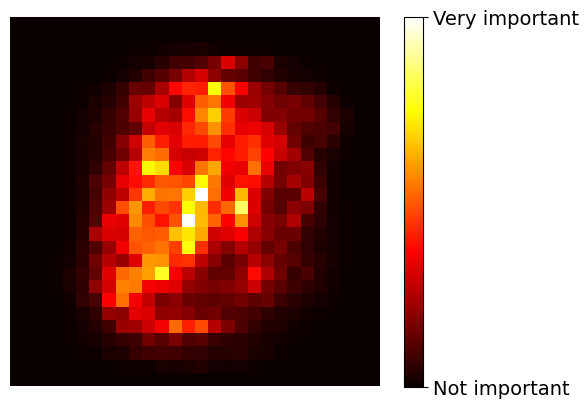

In [10]:
from sklearn.datasets import fetch_openml

X_mnist, y_mnist = fetch_openml("mnist_784", return_X_y=True, as_frame=False, parser="auto")
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rnd_clf.fit(X_mnist, y_mnist)

heatmap_image = rnd_clf.feature_importances_.reshape(28, 28)  # 784개 픽셀 중요도 → 28×28
plt.imshow(heatmap_image, cmap="hot")
cbar = plt.colorbar(ticks=[rnd_clf.feature_importances_.min(), rnd_clf.feature_importances_.max()])
cbar.ax.set_yticklabels(["Not important", "Very important"], fontsize=14)
plt.axis("off")
plt.show()

→ 숫자가 주로 그려지는 가운데 픽셀이 중요하고, 가장자리 픽셀은 거의 중요하지 않습니다.

## **6.5 부스팅**

**부스팅(boosting)** 은 약한 학습기 여러 개를 **순차적으로** 연결해, 앞의 모델을 보완해 나가며 강한 학습기를 만드는 앙상블 방법입니다.

### **6.5.1 AdaBoost**

이전 예측기가 잘못 분류한(과소적합한) 훈련 샘플의 가중치를 높여, 다음 예측기가 어려운 샘플에 점점 더 집중하게 만듭니다.

$$r_j = \frac{\sum_{\hat{y}_j^{(i)} \neq y^{(i)}} w^{(i)}}{\sum_{i=1}^{m} w^{(i)}} \qquad \alpha_j = \eta \log \frac{1 - r_j}{r_j} \qquad w^{(i)} \leftarrow w^{(i)} \exp(\alpha_j) \;\; (\hat{y}_j^{(i)} \neq y^{(i)})$$

- $r_j$: $j$번째 예측기의 가중치 적용 오류율, $\alpha_j$: 예측기 가중치, $\eta$: 학습률

규제를 강하게 한 RBF 커널 SVM 5개를 순서대로 훈련하며 AdaBoost의 샘플 가중치 업데이트를 직접 구현하고, 학습률 1과 0.5의 결정 경계를 비교합니다.

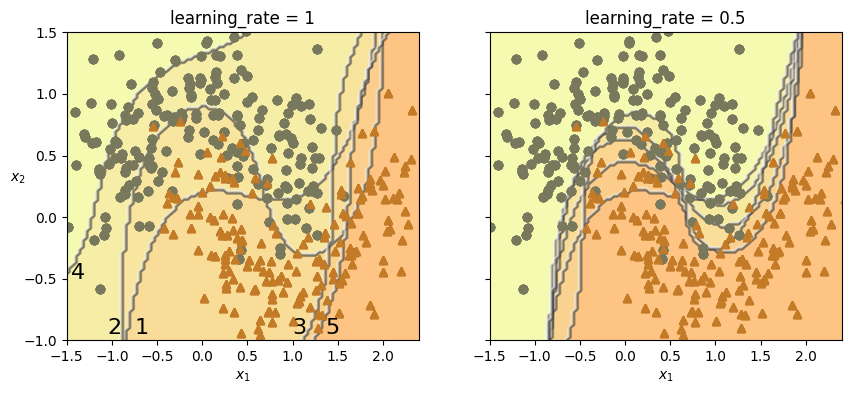

In [11]:
m = len(X_train)  # 샘플 수

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
for subplot, learning_rate in ((0, 1), (1, 0.5)):
    sample_weights = np.ones(m) / m  # 샘플 가중치를 1/m로 초기화
    plt.sca(axes[subplot])
    for i in range(5):
        svm_clf = SVC(C=0.2, gamma=0.6, random_state=42)
        svm_clf.fit(X_train, y_train, sample_weight=sample_weights * m)
        y_pred = svm_clf.predict(X_train)

        error_weights = sample_weights[y_pred != y_train].sum()
        r = error_weights / sample_weights.sum()  # 식 6-1: 가중치 적용 오류율
        alpha = learning_rate * np.log((1 - r) / r)  # 식 6-2: 예측기 가중치
        sample_weights[y_pred != y_train] *= np.exp(alpha)  # 식 6-3: 잘못 분류된 샘플 가중치 증가
        sample_weights /= sample_weights.sum()  # 정규화 (합이 1)

        plot_decision_boundary(svm_clf, X_train, y_train, alpha=0.4)
        plt.title(f"learning_rate = {learning_rate}")
    if subplot == 0:
        plt.text(-0.75, -0.95, "1", fontsize=16)
        plt.text(-1.05, -0.95, "2", fontsize=16)
        plt.text(1.0, -0.95, "3", fontsize=16)
        plt.text(-1.45, -0.5, "4", fontsize=16)
        plt.text(1.36,  -0.95, "5", fontsize=16)
    else:
        plt.ylabel("")
plt.show()

→ 오른쪽(학습률 0.5)은 잘못 분류된 샘플의 가중치가 반복마다 절반 정도만 높아집니다.

> ⚠ 부스팅은 각 예측기가 이전 예측기의 훈련·평가가 끝나야 학습할 수 있어 **병렬화가 불가능**합니다. 그래서 배깅·페이스팅만큼 확장성이 높지 않습니다.

사이킷런은 AdaBoost의 다중 클래스 버전인 **SAMME**를 사용합니다. (클래스가 두 개면 AdaBoost와 동일)

깊이 1인 결정 트리(결정 그루터기) 30개로 `AdaBoostClassifier`를 훈련하고 결정 경계를 그립니다.

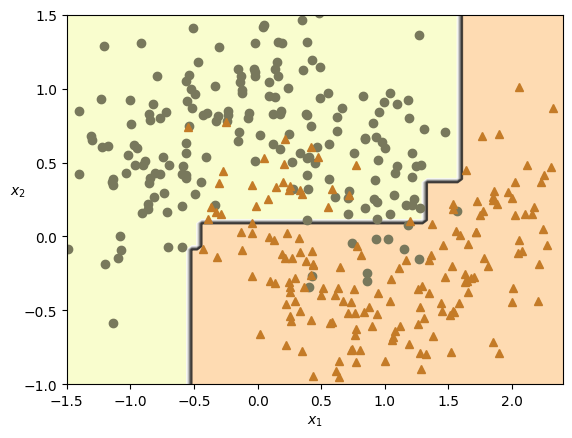

In [12]:
from sklearn.ensemble import AdaBoostClassifier

# 사이킷런 1.6부터 algorithm 매개변수는 폐기 예정(항상 SAMME 사용)이므로 지정하지 않음
ada_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=30,
                             learning_rate=0.5, random_state=42)
ada_clf.fit(X_train, y_train)
plot_decision_boundary(ada_clf, X_train, y_train)
plt.show()

### **6.5.2 그레이디언트 부스팅**

AdaBoost처럼 샘플 가중치를 수정하는 대신, 이전 예측기가 만든 **잔여 오차(residual error)** 에 새 예측기를 학습시킵니다. 결정 트리를 기반 예측기로 쓰면 **그레이디언트 부스티드 회귀 트리(gradient boosted regression tree, GBRT)** 라고 합니다.

잡음이 섞인 2차 함수 데이터셋에서 회귀 트리 3개를 잔여 오차에 차례로 훈련하고, 세 트리의 예측을 더해 새 샘플을 예측합니다.

In [13]:
from sklearn.tree import DecisionTreeRegressor

m = 100  # 샘플 수
rng = np.random.default_rng(seed=42)
X = rng.random((m, 1)) - 0.5
noise = 0.05 * rng.standard_normal(m)
y = 3 * X[:, 0] ** 2 + noise  # y = 3x² + 가우스 잡음

tree_reg1 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg1.fit(X, y)

y2 = y - tree_reg1.predict(X)  # 첫 번째 트리의 잔여 오차
tree_reg2 = DecisionTreeRegressor(max_depth=2, random_state=43)
tree_reg2.fit(X, y2)

y3 = y2 - tree_reg2.predict(X)  # 두 번째 트리의 잔여 오차
tree_reg3 = DecisionTreeRegressor(max_depth=2, random_state=44)
tree_reg3.fit(X, y3)

X_new = np.array([[-0.4], [0.], [0.5]])
sum(tree.predict(X_new) for tree in (tree_reg1, tree_reg2, tree_reg3))  # 모든 트리의 예측을 더함

array([0.57356534, 0.0405142 , 0.66914249])

왼쪽 열은 각 트리의 예측(잔여 오차에 대한 학습), 오른쪽 열은 트리를 하나씩 더해 가는 앙상블의 예측입니다.

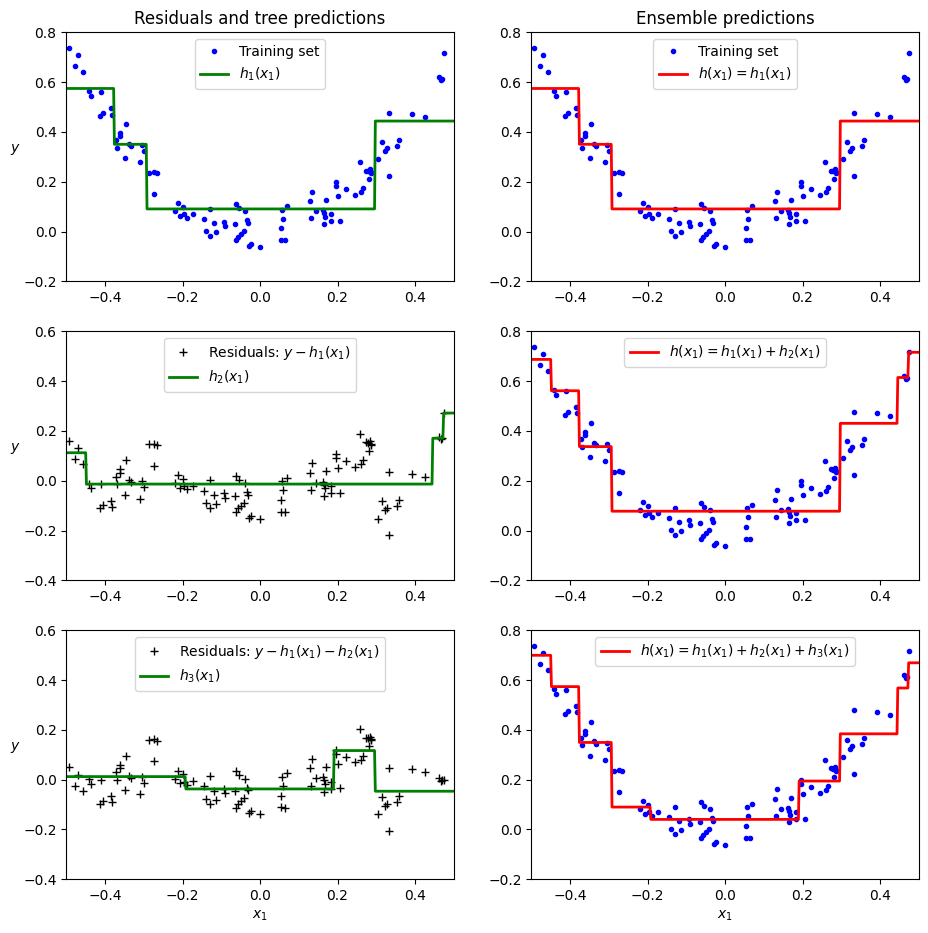

In [14]:
def plot_predictions(regressors, X, y, axes, style, label=None, data_style="b.", data_label=None):
    x1 = np.linspace(axes[0], axes[1], 500)
    y_pred = sum(regressor.predict(x1.reshape(-1, 1)) for regressor in regressors)
    plt.plot(X[:, 0], y, data_style, label=data_label)
    plt.plot(x1, y_pred, style, linewidth=2, label=label)
    if label or data_label:
        plt.legend(loc="upper center")
    plt.axis(axes)

plt.figure(figsize=(11, 11))
plt.subplot(3, 2, 1)
plot_predictions([tree_reg1], X, y, axes=[-0.5, 0.5, -0.2, 0.8], style="g-", label="$h_1(x_1)$", data_label="Training set")
plt.ylabel("$y$  ", rotation=0)
plt.title("Residuals and tree predictions")

plt.subplot(3, 2, 2)
plot_predictions([tree_reg1], X, y, axes=[-0.5, 0.5, -0.2, 0.8], style="r-", label="$h(x_1) = h_1(x_1)$", data_label="Training set")
plt.title("Ensemble predictions")

plt.subplot(3, 2, 3)
plot_predictions([tree_reg2], X, y2, axes=[-0.5, 0.5, -0.4, 0.6], style="g-", label="$h_2(x_1)$", data_style="k+", data_label="Residuals: $y - h_1(x_1)$")
plt.ylabel("$y$  ", rotation=0)

plt.subplot(3, 2, 4)
plot_predictions([tree_reg1, tree_reg2], X, y, axes=[-0.5, 0.5, -0.2, 0.8], style="r-", label="$h(x_1) = h_1(x_1) + h_2(x_1)$")

plt.subplot(3, 2, 5)
plot_predictions([tree_reg3], X, y3, axes=[-0.5, 0.5, -0.4, 0.6], style="g-", label="$h_3(x_1)$", data_style="k+", data_label="Residuals: $y - h_1(x_1) - h_2(x_1)$")
plt.xlabel("$x_1$")
plt.ylabel("$y$  ", rotation=0)

plt.subplot(3, 2, 6)
plot_predictions([tree_reg1, tree_reg2, tree_reg3], X, y, axes=[-0.5, 0.5, -0.2, 0.8], style="r-", label="$h(x_1) = h_1(x_1) + h_2(x_1) + h_3(x_1)$")
plt.xlabel("$x_1$")
plt.show()

→ 트리가 앙상블에 추가될수록 앙상블의 예측이 점차 좋아집니다.

`GradientBoostingRegressor`로 앞과 같은 앙상블(트리 3개, 학습률 1.0)을 만듭니다.

In [15]:
from sklearn.ensemble import GradientBoostingRegressor

gbrt = GradientBoostingRegressor(max_depth=2, n_estimators=3, learning_rate=1.0, random_state=42)
gbrt.fit(X, y);  # 세미콜론: 모델 출력 생략

`learning_rate`를 낮추면(예: 0.05) 트리가 더 많이 필요하지만 일반화 성능이 좋아집니다. 이를 **축소(shrinkage)** 라는 규제 방법이라고 합니다.

학습률 0.05, 최대 트리 500개로 설정하되 `n_iter_no_change=10`으로 조기 종료하는 모델을 훈련하고, 앞의 모델과 예측을 비교합니다.

53


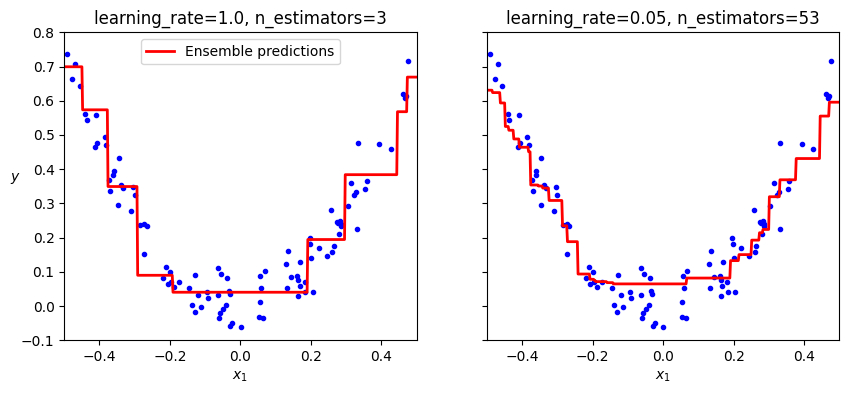

In [16]:
gbrt_best = GradientBoostingRegressor(max_depth=2, learning_rate=0.05, n_estimators=500,
                                      n_iter_no_change=10, random_state=42)
gbrt_best.fit(X, y)
print(gbrt_best.n_estimators_)  # 53 → 조기 종료로 실제 사용한 트리 수

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_predictions([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8], style="r-", label="Ensemble predictions")
plt.title(f"learning_rate={gbrt.learning_rate}, n_estimators={gbrt.n_estimators_}")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)

plt.sca(axes[1])
plot_predictions([gbrt_best], X, y, axes=[-0.5, 0.5, -0.1, 0.8], style="r-")
plt.title(f"learning_rate={gbrt_best.learning_rate}, n_estimators={gbrt_best.n_estimators_}")
plt.xlabel("$x_1$")
plt.show()

→ 왼쪽은 트리가 부족해 훈련 세트를 충분히 학습하지 못했고, 오른쪽은 500개 중 53개에서 조기 종료되어 적정한 개수의 트리를 사용했습니다.

- `n_iter_no_change`: 마지막 N개의 트리가 도움이 되지 않으면 트리 추가를 중지 (검증 세트 크기는 `validation_fraction`, 기본값 10%)
- `subsample`: 각 트리가 사용할 훈련 샘플 비율 (예: 0.25) → **확률적 그레이디언트 부스팅(stochastic gradient boosting)**

### **6.5.3 히스토그램 기반 그레이디언트 부스팅**

**HGB(histogram-based gradient boosting)** 는 입력 특성을 구간(`max_bins`, 기본값 255)으로 나눠 정수로 바꾼 뒤 훈련합니다. 계산 복잡도가 $O(n \times m \times \log(m))$ 대신 $O(b \times m)$이라 대규모 데이터셋에서 훨씬 빠르고, **범주형 특성과 누락된 값을 지원**합니다.

2장의 캘리포니아 주택 데이터셋을 내려받아(이미 있으면 재사용) 훈련 세트를 준비합니다.

In [17]:
from pathlib import Path
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter="data")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()
train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)
housing_labels = train_set["median_house_value"]
housing = train_set.drop("median_house_value", axis=1)

범주형 특성 `ocean_proximity`만 `OrdinalEncoder`로 정수 인코딩하는 파이프라인을 만들고, 10-폴드 교차 검증으로 RMSE를 평가합니다.

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_val_score

hgb_reg = make_pipeline(
    make_column_transformer((OrdinalEncoder(), ["ocean_proximity"]), remainder="passthrough"),
    HistGradientBoostingRegressor(categorical_features=[0], random_state=42)  # 0번 열이 범주형
)
hgb_rmses = -cross_val_score(hgb_reg, housing, housing_labels,
                             scoring="neg_root_mean_squared_error", cv=10)
pd.Series(hgb_rmses).describe()

count       10.000000
mean     47613.307194
std       1295.422509
min      44963.213061
25%      47001.233485
50%      48000.963564
75%      48488.093243
max      49176.368465
dtype: float64

→ 누락된 값 채우기, 스케일 조정, 원-핫 인코딩 없이도 하이퍼파라미터 튜닝 없이 평균 RMSE 약 47,600을 얻었습니다.

> 💡 XGBoost, CatBoost, LightGBM도 최적화된 그레이디언트 부스팅 라이브러리입니다. 랜덤 포레스트 쪽에는 Yggdrasil Decision Forests(YDF)가 있습니다.

## **6.6 스태킹**

**스태킹(stacking, stacked generalization)** 은 예측을 취합하는 함수(투표 등) 대신 취합하는 모델, 즉 **블렌더(blender)** 또는 **메타 학습기(meta learner)** 를 훈련합니다. 블렌더의 훈련 세트는 각 예측기의 `cross_val_predict()` **표본 외(out-of-sample) 예측**으로 만듭니다.

투표 기반 분류기 대신 `StackingClassifier`(최종 예측기: 랜덤 포레스트, 5-폴드 교차 검증)를 moons 데이터셋에 훈련합니다.

In [19]:
from sklearn.ensemble import StackingClassifier

# 6.5.2절에서 X, y는 2차 함수 데이터로 바뀌었지만 X_train, y_train은 moons 데이터 그대로임
stacking_clf = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(random_state=42)),
        ("rf", RandomForestClassifier(random_state=42)),
        ("svc", SVC(probability=True, random_state=42))
    ],
    final_estimator=RandomForestClassifier(random_state=43),
    cv=5  # 교차 검증 폴드 수
)
stacking_clf.fit(X_train, y_train)
print(stacking_clf.score(X_test, y_test))  # 0.928

0.928


→ 92.8%로, 간접 투표 분류기(92%)보다 약간 더 높습니다. 최종 예측기를 지정하지 않으면 `StackingClassifier`는 `LogisticRegression`, `StackingRegressor`는 `RidgeCV`를 사용합니다.

> 💡 랜덤 포레스트, AdaBoost, GBRT, HGB는 대부분의 머신러닝 작업에서 가장 먼저 시도해 볼 모델이며, 특히 여러 종류의 특성이 섞인 표 형식 데이터에서 뛰어납니다.